# Phân tích khám phá dữ liệu giao thông từ camera
**Môn học:** Python for Data Science  
**Nhóm:** Nguyễn Tuấn Thịnh (25139048)

Notebook này phân tích hai đợt thu `data1.csv` và `data2.csv`: chất lượng, độ phủ thời gian,
phân bố phương tiện, WTI, quan hệ giữa các biến và điều kiện tạo dữ liệu dự báo.

**Đơn vị quan sát:** một ảnh camera đã qua detector. Số xe là số phát hiện trong ảnh,
không phải lưu lượng xe đi qua giao lộ. WTI là điểm trọng số, chưa phải nhãn ùn tắc.
Notebook không huấn luyện mô hình; phần train và đánh giá nằm trong `pipeline_giao_thong.py`.

**Cách chạy:** giải nén đầy đủ gói nộp, mở notebook trong Jupyter/VS Code, chọn môi trường
có numpy, pandas, matplotlib rồi **Run All** từ đầu. Có thể chạy từ thư mục gốc dự án hoặc `reports`.
Các bảng và hình dưới đây được tính từ CSV, không lấy số liệu có sẵn trong báo cáo Word.


## 1. Khởi tạo và đọc dữ liệu
Tìm dữ liệu theo cấu trúc dự án hoặc gói nộp. Giữ từng capture riêng, không nối xuyên qua
khoảng ngắt gần một tuần để tạo rolling/lag. Thời gian được đọc theo giờ địa phương ghi trong CSV.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in candidates if (p / "data/data1.csv").is_file()
             and (p / "core/traffic_features.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục gốc gói nộp hoặc reports của dự án.")
sys.path.insert(0, str(ROOT))
from core.traffic_features import (
    validate_samples, read_minutes, supervised_data, FEATURE_NAMES,
    TARGET_COLUMN, CONGESTION_THRESHOLD, FORECAST_HORIZON,
)
plt.rcParams.update({"figure.figsize": (11, 4.5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.18})
COLORS = {"data1": "#087f8c", "data2": "#db7c26"}
paths = {name: ROOT / "data" / f"{name}.csv" for name in ("data1", "data2")}
raw = {name: pd.read_csv(path) for name, path in paths.items()}
print("Thư mục dữ liệu:", ROOT / "data")
for name, frame in raw.items():
    print(f"\n{name}: {frame.shape[0]:,} dòng, {frame.shape[1]} cột")
    print(frame.head().to_string(index=False))


Thư mục dữ liệu: Z:\Dev_projects\Python\Data_Science\Traffic_congestion_prediction\data

data1: 7,044 dòng, 9 cột
          timestamp  person  car  motorbike  bus  truck  total   WTI   WTI_norm
2026-09-21 17:41:40      15   23         18    4      1     46 144.0 698.421255
2026-09-21 17:41:43      14   25         13    4      1     43 147.0 703.275876
2026-09-21 17:41:52      11   21          8    5      2     36 139.0 640.917590
2026-09-21 17:42:04       4   17          7    0      2     26  87.0 373.737807
2026-09-21 17:42:16       5   18          6    5      1     30 119.0 527.644477

data2: 7,065 dòng, 9 cột
          timestamp  person  car  motorbike  bus  truck  total  WTI   WTI_norm
2026-09-28 22:39:52       2    1          0    0      1      2 10.0  20.986123
2026-09-28 22:39:56      13    5         11    0      1     17 37.0 143.943755
2026-09-28 22:40:10       8    8          5    0      1     14 43.0 159.446159
2026-09-28 22:40:24       3    6          3    0      3     12 4

| Cột | Ý nghĩa |
|---|---|
| timestamp | Thời điểm nhận/ghi mẫu; CSV không có thông tin múi giờ |
| person | Số phát hiện người, không dùng trong WTI |
| car, motorbike, bus, truck | Số phát hiện theo loại phương tiện |
| total | Tổng bốn loại xe |
| WTI | 4 × car + motorbike + 7 × bus + 6 × truck |
| WTI_norm | WTI × (1 + ln(1 + total)), không chuẩn hóa về 0–1 |

Nguồn thu là camera giao thông công cộng TP.HCM (`core/Get_frame.py`, `get_data.py`).
Ảnh được giải mã bằng OpenCV, nhận diện bằng YOLO/Supervision rồi ghi số đếm vào CSV.
CSV không có ảnh và camera_id để xác minh riêng từng mẫu.


## 2. Kiểm tra chất lượng dữ liệu
Kiểm tra ô trống, timestamp không hợp lệ/trùng, số đếm nguyên không âm và công thức chỉ số.
Không tự loại các dòng WTI lớn trước khi biết đó là lỗi đo hay biến động giao thông thật.


In [2]:
quality = []
for name, frame in raw.items():
    times = pd.to_datetime(frame.timestamp, errors="coerce")
    counts = frame[["car", "motorbike", "bus", "truck", "total"]]
    expected_total = counts[["car", "motorbike", "bus", "truck"]].sum(axis=1)
    expected_wti = 4*frame.car + frame.motorbike + 7*frame.bus + 6*frame.truck
    expected_norm = expected_wti * (1 + np.log1p(expected_total))
    quality.append({
        "capture": name, "missing_cells": int(frame.isna().sum().sum()),
        "invalid_time": int(times.isna().sum()),
        "duplicate_time": int(times.duplicated().sum()),
        "duplicate_rows": int(frame.duplicated().sum()),
        "negative_counts": int((counts < 0).sum().sum()),
        "noninteger_counts": int((counts != np.floor(counts)).sum().sum()),
        "wrong_total": int((frame.total != expected_total).sum()),
        "wrong_WTI": int((~np.isclose(frame.WTI, expected_wti)).sum()),
        "wrong_WTI_norm": int((~np.isclose(frame.WTI_norm, expected_norm)).sum()),
    })
    validate_samples(frame)  # Cùng hàm kiểm tra với pipeline triển khai.
quality = pd.DataFrame(quality).set_index("capture")
print(quality.T.to_string())
samples = {name: frame.assign(timestamp=pd.to_datetime(frame.timestamp)).sort_values("timestamp")
           for name, frame in raw.items()}


capture            data1  data2
missing_cells          0      0
invalid_time           0      0
duplicate_time         0      0
duplicate_rows         0      0
negative_counts        0      0
noninteger_counts      0      0
wrong_total            0      0
wrong_WTI              0      0
wrong_WTI_norm         0      0


## 3. Độ phủ thời gian và dữ liệu mất
Không có ô trống trong CSV không đồng nghĩa không mất mẫu: khoảng thời gian camera ngừng gửi ảnh
sẽ không tạo dòng CSV. Vì vậy cần xem khoảng cách timestamp và đưa dữ liệu về lưới một phút.
Khoảng [10:00, 10:01) được gắn nhãn 10:01; loại hai phút biên chưa đầy đủ như pipeline train.


In [3]:
minutes = {name: read_minutes(path) for name, path in paths.items()}
coverage = []
for name, frame in samples.items():
    delta = frame.timestamp.diff().dt.total_seconds().dropna()
    minute = minutes[name]
    coverage.append({"capture": name, "samples": len(frame),
                     "start": frame.timestamp.min(), "end": frame.timestamp.max(),
                     "median_gap_s": delta.median(), "p95_gap_s": delta.quantile(.95),
                     "max_gap_s": delta.max(), "minutes": len(minute),
                     "missing_minutes": int((minute.samples_per_minute == 0).sum()),
                     "sparse_1_or_2": int(minute.samples_per_minute.between(1, 2).sum())})
    print(f"\n{name} - các phút mất mẫu:")
    print(minute.index[minute.samples_per_minute == 0].tolist())
coverage = pd.DataFrame(coverage).set_index("capture")
print("\nTóm tắt độ phủ:")
print(coverage.T.to_string())



data1 - các phút mất mẫu:
[Timestamp('2026-09-22 10:22:00'), Timestamp('2026-09-22 16:02:00')]

data2 - các phút mất mẫu:
[Timestamp('2026-09-29 10:02:00'), Timestamp('2026-09-29 16:06:00'), Timestamp('2026-09-29 20:02:00')]

Tóm tắt độ phủ:
capture                        data1                data2
samples                         7044                 7065
start            2026-09-21 17:41:40  2026-09-28 22:39:52
end              2026-09-22 17:41:32  2026-09-29 22:39:43
median_gap_s                    12.0                 12.0
p95_gap_s                       14.0                 14.0
max_gap_s                      147.0                170.0
minutes                         1439                 1439
missing_minutes                    2                    3
sparse_1_or_2                      4                    6


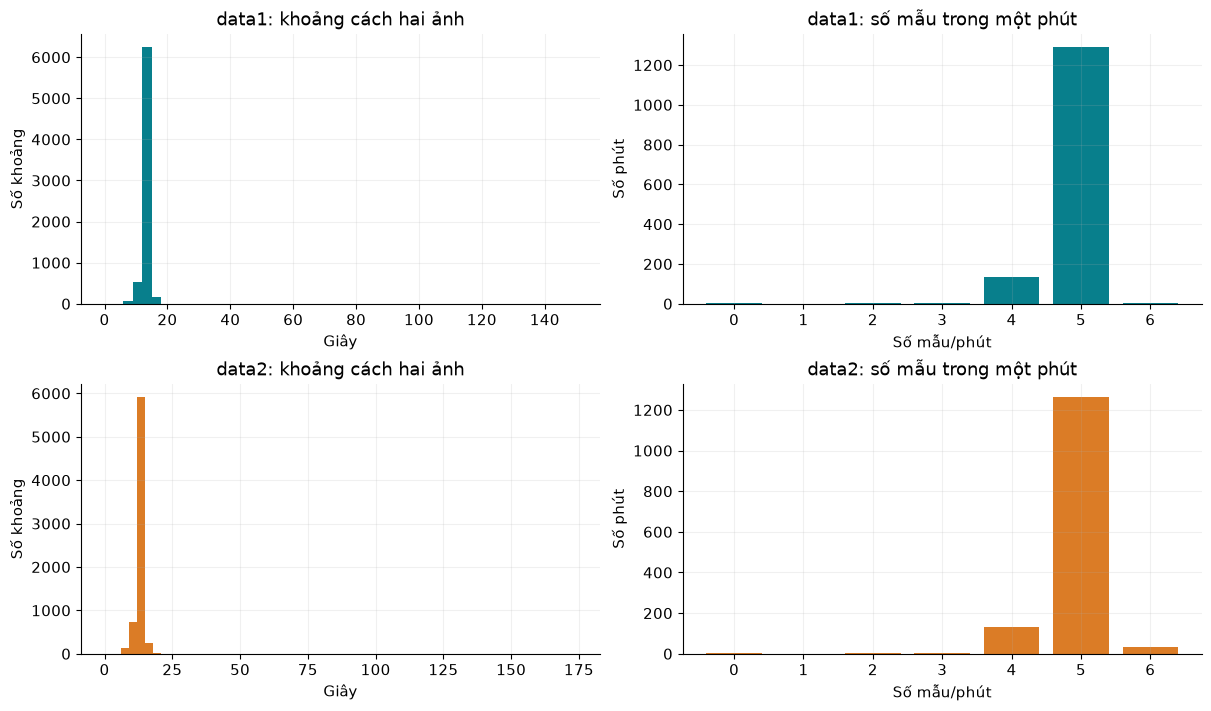

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), constrained_layout=True)
for row, (name, frame) in enumerate(samples.items()):
    gap = frame.timestamp.diff().dt.total_seconds().dropna()
    axes[row, 0].hist(gap, bins=np.arange(0, gap.max()+6, 3), color=COLORS[name])
    axes[row, 0].set(title=f"{name}: khoảng cách hai ảnh", xlabel="Giây", ylabel="Số khoảng")
    counts = minutes[name].samples_per_minute.value_counts().sort_index()
    axes[row, 1].bar(counts.index, counts.values, color=COLORS[name])
    axes[row, 1].set(title=f"{name}: số mẫu trong một phút", xlabel="Số mẫu/phút", ylabel="Số phút")
plt.show()


**Diễn giải:** các khoảng dài có thể đến từ nguồn ảnh, mạng hoặc xử lý; CSV không đủ log
để quy nguyên nhân. Phút mất mẫu giữ NaN, không được điền 0 để mô tả là đường vắng.
Nhánh model trực tiếp yêu cầu ít nhất 3 mẫu/phút; notebook vẫn giữ phút thưa để chỉ ra chất lượng dữ liệu.


## 4. Phân bố phương tiện và chỉ số WTI
Thống kê phần này tính trên ảnh, chưa tổng hợp phút. Tỷ trọng theo lớp là tỷ trọng lượt phát hiện;
một phương tiện có thể xuất hiện ở nhiều ảnh nên tổng phát hiện không phải số xe duy nhất.


In [5]:
stats = pd.concat({name: frame[["total", "WTI"]].describe(percentiles=[.25, .5, .75]).T
                   for name, frame in samples.items()}, names=["capture", "signal"])
print(stats.round(2).to_string())
vehicle_cols = ["car", "motorbike", "bus", "truck"]
shares = pd.DataFrame({name: frame[vehicle_cols].sum()/frame.total.sum()*100
                       for name, frame in samples.items()}).T
print("\nTỷ trọng lượt phát hiện (%):")
print(shares.round(2).to_string())
for name, frame in samples.items():
    print(f"{name}: {int((frame.total == 0).sum())} ảnh không phát hiện xe; "
          f"{(frame.WTI > CONGESTION_THRESHOLD).mean():.2%} ảnh WTI > 100")


                 count   mean    std  min   25%   50%    75%    max
capture signal                                                     
data1   total   7044.0  22.37  15.38  0.0   7.0  23.0   36.0   59.0
        WTI     7044.0  75.08  49.57  0.0  30.0  77.0  114.0  267.0
data2   total   7065.0  22.95  13.54  0.0  11.0  24.0   34.0   59.0
        WTI     7065.0  73.49  44.37  0.0  34.0  74.0  109.0  217.0

Tỷ trọng lượt phát hiện (%):
         car  motorbike   bus  truck
data1  52.60      32.73  4.47  10.19
data2  49.61      36.89  3.86   9.64
data1: 267 ảnh không phát hiện xe; 35.18% ảnh WTI > 100
data2: 86 ảnh không phát hiện xe; 31.82% ảnh WTI > 100


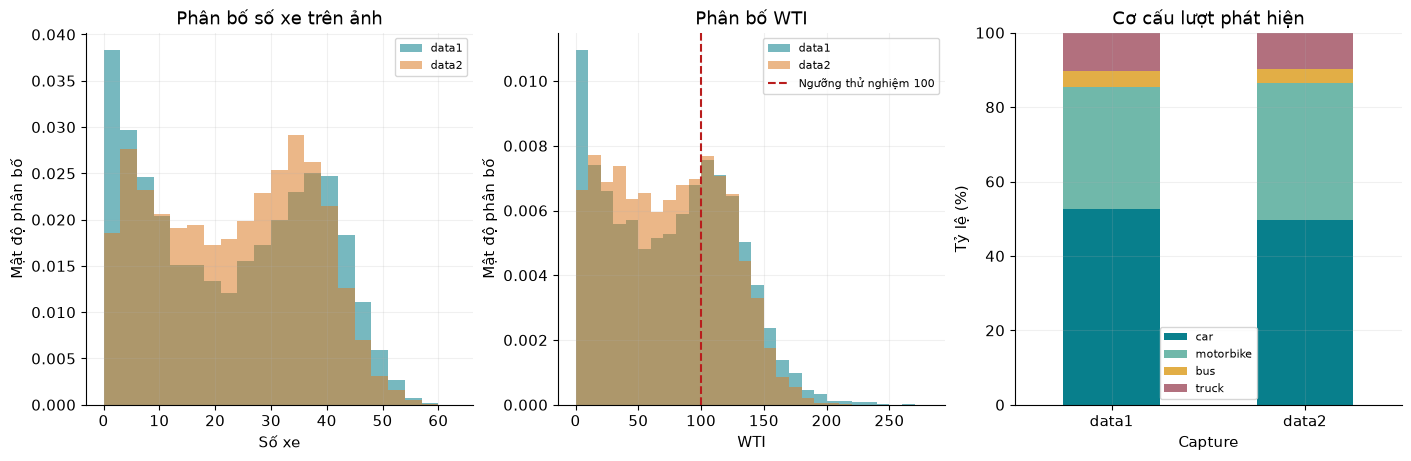

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), constrained_layout=True)
for name, frame in samples.items():
    axes[0].hist(frame.total, bins=np.arange(0, 65, 3), density=True, alpha=.55,
                 label=name, color=COLORS[name])
    axes[1].hist(frame.WTI, bins=np.arange(0, 281, 10), density=True, alpha=.55,
                 label=name, color=COLORS[name])
axes[0].set(title="Phân bố số xe trên ảnh", xlabel="Số xe", ylabel="Mật độ phân bố")
axes[1].set(title="Phân bố WTI", xlabel="WTI", ylabel="Mật độ phân bố")
axes[1].axvline(CONGESTION_THRESHOLD, color="#b91c1c", ls="--", label="Ngưỡng thử nghiệm 100")
shares.plot.bar(stacked=True, ax=axes[2], color=["#087f8c", "#70b8aa", "#e2ae46", "#b2707e"])
axes[2].set(title="Cơ cấu lượt phát hiện", ylabel="Tỷ lệ (%)", xlabel="Capture", ylim=(0, 100))
axes[2].tick_params(axis="x", rotation=0)
for ax in axes: ax.legend(fontsize=8)
plt.show()


## 5. Diễn biến theo thời gian và theo giờ
Đường WTI trung bình phút giúp giảm ảnh hưởng của nhịp ảnh không đều. Khoảng thiếu được giữ đứt.
Đường trung bình trượt 15 phút dưới đây chỉ phục vụ EDA, không thay thế phép làm mượt 3 phút ở đầu ra model.


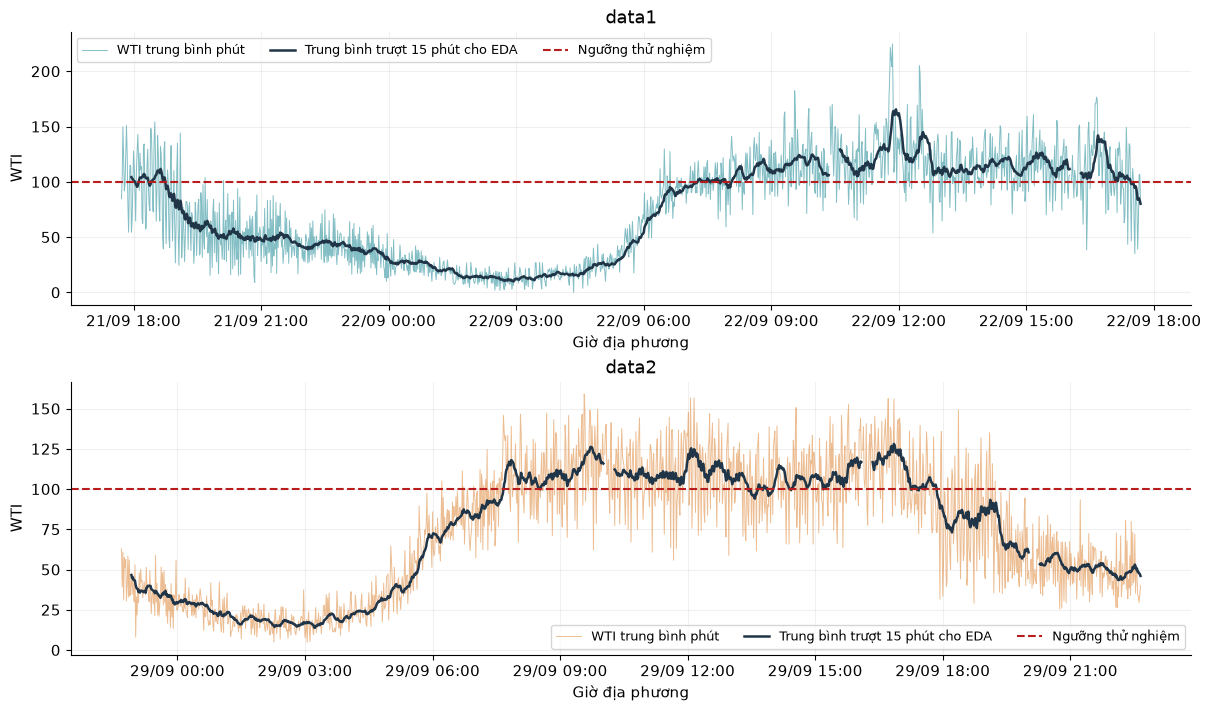

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
for ax, (name, minute) in zip(axes, minutes.items()):
    ax.plot(minute.index, minute.WTI_mean, color=COLORS[name], alpha=.5, lw=.7, label="WTI trung bình phút")
    ax.plot(minute.index, minute.WTI_mean.rolling(15, min_periods=15).mean(),
            color="#203547", lw=1.8, label="Trung bình trượt 15 phút cho EDA")
    ax.axhline(CONGESTION_THRESHOLD, color="#b91c1c", ls="--", label="Ngưỡng thử nghiệm")
    ax.set(title=name, ylabel="WTI", xlabel="Giờ địa phương")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))
    ax.legend(fontsize=9, ncol=3)
plt.show()


WTI trung bình theo giờ (các phút hoàn tất):
            data1   data2
timestamp                
0           26.57   26.64
1           17.14   19.32
2           12.45   16.73
3           14.80   18.23
4           19.92   27.35
5           39.07   52.36
6           85.22   79.70
7           99.31   99.69
8          110.90  106.49
9          118.48  115.42
10         114.98  110.57
11         132.35  109.38
12         122.57  112.46
13         110.07  101.60
14         115.08  107.14
15         117.13  108.58
16         115.77  120.39
17          97.31   99.46
18          97.62   80.93
19          61.01   69.94
20          50.52   53.72
21          46.72   50.45
22          43.46   45.77
23          35.75   34.39


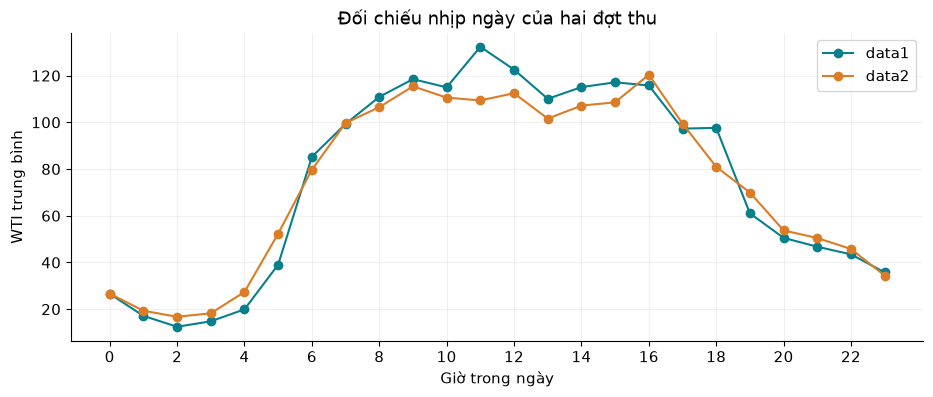

data1: giờ thấp nhất 02h (12.45 WTI); cao nhất 11h (132.35 WTI).
data2: giờ thấp nhất 02h (16.73 WTI); cao nhất 16h (120.39 WTI).


In [8]:
# Group theo giờ của phút HOÀN TẤT, khác thống kê trọng số theo từng ảnh.
hourly = pd.DataFrame({name: minute.groupby(minute.index.hour).WTI_mean.mean()
                       for name, minute in minutes.items()})
print("WTI trung bình theo giờ (các phút hoàn tất):")
print(hourly.round(2).to_string())
fig, ax = plt.subplots(figsize=(11, 4))
for name in hourly:
    ax.plot(hourly.index, hourly[name], marker="o", label=name, color=COLORS[name])
ax.set(xticks=range(0, 24, 2), xlabel="Giờ trong ngày", ylabel="WTI trung bình", title="Đối chiếu nhịp ngày của hai đợt thu")
ax.legend(); plt.show()
for name in hourly:
    print(f"{name}: giờ thấp nhất {hourly[name].idxmin():02d}h ({hourly[name].min():.2f} WTI); "
          f"cao nhất {hourly[name].idxmax():02d}h ({hourly[name].max():.2f} WTI).")


**Nhận xét:** hai đợt đều có mức thấp ban đêm và tăng vào ban ngày, nhưng vị trí đỉnh khác nhau.
Chỉ hai đợt gần 24 giờ chưa đủ để học quy luật thứ trong tuần. Các giờ ở biên capture chỉ bao phủ
một phần thời gian; trung bình trên đây không gia quyền theo độ dài khoảng giữa ảnh.
Đỉnh WTI không nhất thiết trùng đỉnh tổng xe do trọng số khác nhau theo loại phương tiện.


## 6. Tương quan, chỉ số dẫn xuất và giá trị cực trị
Tương quan cao giữa WTI, total và WTI_norm phần lớn có thể đến từ công thức tạo biến.
Không dùng tương quan này làm bằng chứng mô hình đã học được ùn tắc. Target cần là WTI tương lai,
không phải WTI cùng thời điểm được tính sẵn từ số xe hiện tại.


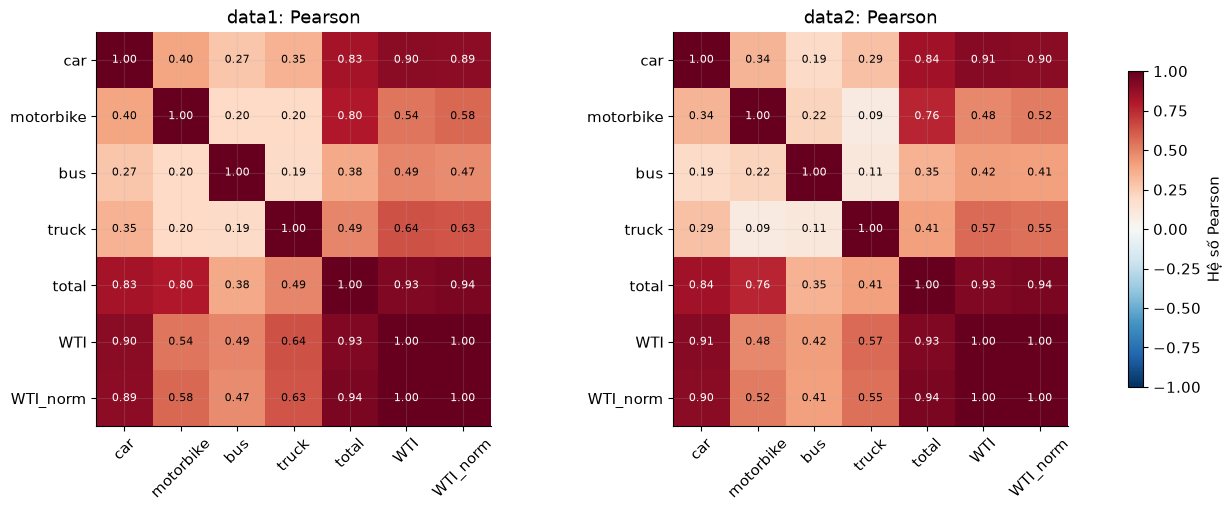

In [9]:
columns = ["car", "motorbike", "bus", "truck", "total", "WTI", "WTI_norm"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, (name, frame) in zip(axes, samples.items()):
    corr = frame[columns].corr()
    im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
    ax.set(xticks=range(len(columns)), yticks=range(len(columns)),
           xticklabels=columns, yticklabels=columns, title=f"{name}: Pearson")
    ax.tick_params(axis="x", rotation=45)
    for i in range(len(columns)):
        for j in range(len(columns)):
            ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if abs(corr.iloc[i,j])>.65 else "black")
fig.colorbar(im, ax=axes, shrink=.8, label="Hệ số Pearson")
plt.show()


In [10]:
# Quy tắc IQR chỉ gắn cờ, KHÔNG xóa dòng hoặc coi đây là lỗi detector.
outlier_summary = []
for name, frame in samples.items():
    q1, q3 = frame.WTI.quantile([.25, .75]); iqr = q3-q1
    lower, upper = q1-1.5*iqr, q3+1.5*iqr
    flag = (frame.WTI < lower) | (frame.WTI > upper)
    outlier_summary.append({"capture": name, "IQR_lower": lower, "IQR_upper": upper,
                            "flagged_rows": int(flag.sum()), "max_WTI": frame.WTI.max()})
    print(f"\n{name}: năm ảnh có WTI lớn nhất")
    print(frame.nlargest(5, "WTI")[["timestamp", *vehicle_cols, "total", "WTI"]].to_string(index=False))
print("\nGắn cờ IQR:")
print(pd.DataFrame(outlier_summary).to_string(index=False))



data1: năm ảnh có WTI lớn nhất
          timestamp  car  motorbike  bus  truck  total   WTI
2026-09-22 11:50:29   24          1    8     19     52 267.0
2026-09-22 11:50:41   21          0    8     17     46 242.0
2026-09-22 11:47:11   27          2    3     18     50 239.0
2026-09-22 11:48:12   29          3    2     17     51 235.0
2026-09-22 09:33:10   35          5    5      9     54 234.0

data2: năm ảnh có WTI lớn nhất
          timestamp  car  motorbike  bus  truck  total   WTI
2026-09-29 09:33:53   32          9    2     11     54 217.0
2026-09-29 12:13:07   25          5    2     15     47 209.0
2026-09-29 13:54:46   19          6    3     17     45 205.0
2026-09-29 16:56:08   38          3    2      6     49 205.0
2026-09-29 11:29:02   18         11    2     17     48 199.0

Gắn cờ IQR:
capture  IQR_lower  IQR_upper  flagged_rows  max_WTI
  data1      -96.0      240.0             2    267.0
  data2      -78.5      221.5             0    217.0


Các điểm cực trị cần ảnh nguồn hoặc nhãn đối chiếu mới xác định được nguyên nhân.
WTI_norm là phép khuếch đại theo log(total), không phải MinMax scaling. Pipeline dự báo giữ WTI gốc
và không dùng WTI_norm, giúp MAE/threshold cùng một đơn vị dễ diễn giải.


## 7. Từ EDA đến dữ liệu dự báo
Sử dụng đúng hàm chung của dự án: 61 feature gồm 11 thống kê phút hiện tại, 16 lag,
26 thống kê trượt, 6 slope và 2 biến giờ sin/cos. Target là 60 WTI của các phút tiếp theo.
Cần 61 điểm lịch sử vì lag 60 vẫn cần giá trị hiện tại.

Ở bước này chỉ tạo dữ liệu, không fit hoặc chọn tham số dựa trên data2.


In [11]:
supervised = {name: supervised_data(minute) for name, minute in minutes.items()}
for name, (X, y) in supervised.items():
    print(f"{name}: X={X.shape}, y={y.shape}; origin {X.index.min()} -> {X.index.max()}")
    assert list(X.columns) == FEATURE_NAMES
    assert X.shape[1] == 61 and y.shape[1] == 60
    assert not X.isna().any().any() and not y.isna().any().any()
print("\n61 đặc trưng:", ", ".join(FEATURE_NAMES))
X_train, y_train = supervised["data1"]
validation_start = X_train.index[int(len(X_train)*.8)]
fit_mask = X_train.index + pd.Timedelta(minutes=FORECAST_HORIZON) < validation_start
validation_mask = X_train.index >= validation_start
print("\nFit origins:", int(fit_mask.sum()), "Validation origins:", int(validation_mask.sum()))
print("Origin fit cuối:", X_train.index[fit_mask][-1])
print("Target fit cuối kết thúc:", X_train.index[fit_mask][-1] + pd.Timedelta(minutes=60))
print("Origin validation đầu:", validation_start)
print("Khoảng cách phút giữa cuối data1 và đầu data2:",
      (minutes["data2"].index.min()-minutes["data1"].index.max()).total_seconds()/60)


data1: X=(1098, 61), y=(1098, 60); origin 2026-09-21 18:43:00 -> 2026-09-22 15:01:00
data2: X=(956, 61), y=(956, 60); origin 2026-09-28 23:41:00 -> 2026-09-29 21:39:00

61 đặc trưng: car_mean, motorbike_mean, bus_mean, truck_mean, total_mean, WTI_mean, total_std, total_max, WTI_std, WTI_max, samples_per_minute, total_lag_1, total_lag_2, total_lag_3, total_lag_5, total_lag_10, total_lag_15, total_lag_30, total_lag_60, total_mean_5, total_mean_15, total_mean_30, total_mean_60, total_std_5, total_std_15, total_std_30, total_min_5, total_min_15, total_min_30, total_max_5, total_max_15, total_max_30, total_slope_5, total_slope_15, total_slope_30, WTI_lag_1, WTI_lag_2, WTI_lag_3, WTI_lag_5, WTI_lag_10, WTI_lag_15, WTI_lag_30, WTI_lag_60, WTI_mean_5, WTI_mean_15, WTI_mean_30, WTI_mean_60, WTI_std_5, WTI_std_15, WTI_std_30, WTI_min_5, WTI_min_15, WTI_min_30, WTI_max_5, WTI_max_15, WTI_max_30, WTI_slope_5, WTI_slope_15, WTI_slope_30, hour_sin, hour_cos

Fit origins: 818 Validation origins: 220


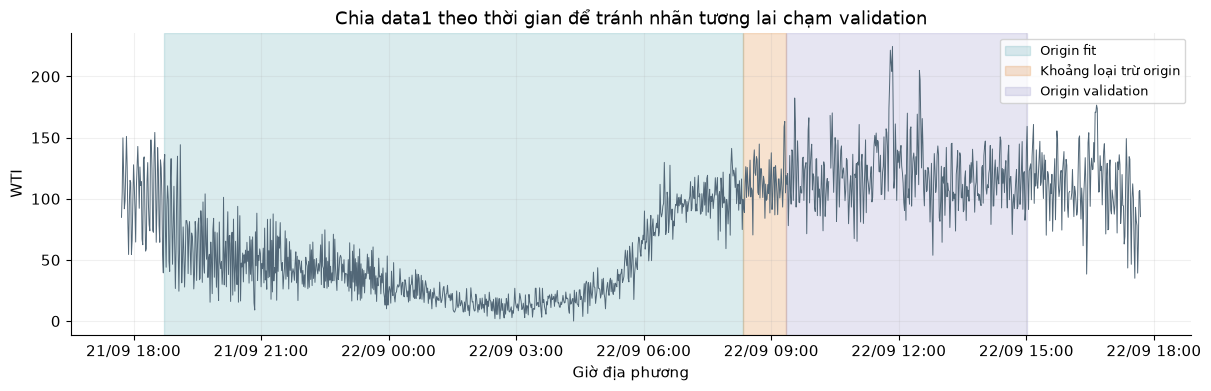

In [12]:
fig, ax = plt.subplots(figsize=(12, 3.8), constrained_layout=True)
series = minutes["data1"].WTI_mean
ax.plot(series.index, series, color="#526777", lw=.7)
ax.axvspan(X_train.index[fit_mask][0], X_train.index[fit_mask][-1], color="#087f8c", alpha=.15, label="Origin fit")
ax.axvspan(X_train.index[fit_mask][-1], validation_start, color="#db7c26", alpha=.22, label="Khoảng loại trừ origin")
ax.axvspan(validation_start, X_train.index[validation_mask][-1], color="#7772b7", alpha=.18, label="Origin validation")
ax.set(title="Chia data1 theo thời gian để tránh nhãn tương lai chạm validation",
       ylabel="WTI", xlabel="Giờ địa phương")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m %H:%M"))
ax.legend(fontsize=9); plt.show()


**Hệ quả đối với mô hình:** không random shuffle các cửa sổ chồng lấn. Các origin gần nhau
không phải tình huống độc lập. Điều kiện offline hiện giữ phút có ít nhất một mẫu, còn nhánh model
live yêu cầu ít nhất ba mẫu/phút; phải nêu khác biệt này khi so sánh độ bao phủ đánh giá với vận hành.

Mô hình ở file Python là HGB đa đầu ra, so sánh target absolute/delta trên validation data1,
refit data1 rồi đánh giá data2 với persistence, slope 15 phút và tham chiếu cùng giờ.


## 8. Kết quả EDA và giới hạn
- Dữ liệu gồm hai capture gần 24 giờ; các bảng phía trên cho thấy quy mô và khoảng thiếu thực tế.
- Kiểm tra công thức giúp phát hiện dữ liệu hỏng, nhưng không chứng minh detector đếm đúng.
- Số lượng và thành phần xe thay đổi theo thời gian; WTI giữ thông tin trọng số theo loại xe.
- Mất mẫu cần được giữ rõ ràng; không thay bằng 0 hoặc dữ liệu tương lai để tạo lịch sử giả.
- Chưa có camera_id trong CSV, tốc độ, ROI, nhãn thời tiết hoặc nhãn ùn tắc thực tế.
- Đề xuất tiếp theo: thu thêm ngày, gán nhãn ảnh/trạng thái giao thông và giữ một capture mới để kiểm tra cuối.



